In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from pathlib import Path

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / "data" / "IndianRoads_dataset.xlsx"
if not DATA_PATH.exists():
    DATA_PATH = BASE_DIR.parent / "data" / "IndianRoads_dataset.xlsx"

df = pd.read_excel(DATA_PATH)
df.head(5)

,accident_id,city,state,latitude,longitude,date,time,day,is_weekend,road_type,...,visibility,temperature,traffic_signal,traffic_density,cause,vehicles_involved,is_peak_hour,casualties,accident_severity,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,05:00:00,Sunday,1,highway,...,low,32,1,high,weather,2,0,2,fatal,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,04:00:00,Sunday,1,urban,...,high,34,0,low,weather,4,0,3,major,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00:00,Wednesday,0,urban,...,low,21,0,medium,weather,1,0,1,minor,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00:00,Sunday,1,urban,...,low,30,1,high,distraction,5,0,2,minor,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00:00,Thursday,0,highway,...,high,24,1,low,distraction,2,0,1,minor,0.10


In [3]:
df.shape

(20000, 22)

In [4]:
df.shape[0]

20000

In [5]:
df.shape[1]

22

In [6]:
df.columns

Index(['accident_id', 'city', 'state', 'latitude', 'longitude', 'date', 'time',
       'day', 'is_weekend', 'road_type', 'lanes', 'weather', 'visibility',
       'temperature', 'traffic_signal', 'traffic_density', 'cause',
       'vehicles_involved', 'is_peak_hour', 'casualties', 'accident_severity',
       'risk_score'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   accident_id        20000 non-null  int64         
 1   city               20000 non-null  str           
 2   state              20000 non-null  str           
 3   latitude           20000 non-null  float64       
 4   longitude          20000 non-null  float64       
 5   date               20000 non-null  datetime64[us]
 6   time               20000 non-null  object        
 7   day                20000 non-null  str           
 8   is_weekend         20000 non-null  int64         
 9   road_type          20000 non-null  str           
 10  lanes              20000 non-null  int64         
 11  weather            20000 non-null  str           
 12  visibility         20000 non-null  str           
 13  temperature        20000 non-null  int64         
 14  traffic_signal   

In [8]:
df.dtypes

accident_id                   int64
city                            str
state                           str
latitude                    float64
longitude                   float64
date                 datetime64[us]
time                         object
day                             str
is_weekend                    int64
road_type                       str
lanes                         int64
weather                         str
visibility                      str
temperature                   int64
traffic_signal                int64
traffic_density                 str
cause                           str
vehicles_involved             int64
is_peak_hour                  int64
casualties                    int64
accident_severity               str
risk_score                  float64
dtype: object

In [9]:
df.describe()

,accident_id,latitude,longitude,date,is_weekend,lanes,temperature,traffic_signal,vehicles_involved,is_peak_hour,casualties,risk_score
count,20000.000000,20000.000000,20000.000000,20000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,9999.500000,20.389207,78.173330,2023-08-22 07:04:48,0.286150,3.493950,27.579600,0.499850,2.992000,0.247400,1.726450,0.437585
min,0.000000,12.800172,72.700017,2022-01-01 00:00:00,0.000000,1.000000,15.000000,0.000000,1.000000,0.000000,0.000000,0.100000
25%,4999.750000,13.198653,73.997979,2022-10-25 00:00:00,0.000000,2.000000,21.000000,0.000000,2.000000,0.000000,1.000000,0.250000
50%,9999.500000,18.812008,77.297000,2023-08-21 00:00:00,0.000000,4.000000,28.000000,0.000000,3.000000,0.000000,1.000000,0.450000
75%,14999.250000,28.402467,80.111089,2024-06-21 00:00:00,1.000000,5.000000,34.000000,1.000000,4.000000,0.000000,3.000000,0.600000
max,19999.000000,30.799960,88.499861,2025-04-15 00:00:00,1.000000,6.000000,40.000000,1.000000,5.000000,1.000000,5.000000,1.000000
std,5773.647028,6.165791,4.485967,NaN,0.451972,1.705406,7.454746,0.500012,1.415534,0.431512,1.489104,0.218130


In [10]:
df.isnull().any()

accident_id          False
city                 False
state                False
latitude             False
longitude            False
date                 False
time                 False
day                  False
is_weekend           False
road_type            False
lanes                False
weather              False
visibility           False
temperature          False
traffic_signal       False
traffic_density      False
cause                False
vehicles_involved    False
is_peak_hour         False
casualties           False
accident_severity    False
risk_score           False
dtype: bool

In [11]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
19995    False
19996    False
19997    False
19998    False
19999    False
Length: 20000, dtype: bool

In [74]:
#Correcting inconsistent values
df["state"] = df["state"].str.strip().str.title()

In [12]:
df["accident_severity"].unique()

<ArrowStringArray>
['fatal', 'major', 'minor']
Length: 3, dtype: str

In [13]:
df["road_type"].unique()

<ArrowStringArray>
['highway', 'urban', 'rural']
Length: 3, dtype: str

In [14]:
df["visibility"].unique()

<ArrowStringArray>
['low', 'high', 'medium']
Length: 3, dtype: str

In [15]:
df["traffic_density"].unique()

<ArrowStringArray>
['high', 'low', 'medium']
Length: 3, dtype: str

In [16]:
df["cause"].unique()

<ArrowStringArray>
['weather', 'distraction', 'overspeeding', 'drunk driving', 'poor road']
Length: 5, dtype: str

In [17]:
df["accident_severity"].value_counts()

accident_severity
minor    11025
major     5988
fatal     2987
Name: count, dtype: int64

In [18]:
df["road_type"].value_counts()

road_type
urban      6745
rural      6639
highway    6616
Name: count, dtype: int64

In [21]:
#Latitude:   8° to 37°
#Longitude: 68° to 97°

In [20]:
df["latitude"].min(), df["latitude"].max()

(np.float64(12.800172), np.float64(30.79996))

In [22]:
df["longitude"].min(), df["longitude"].max()

(np.float64(72.700017), np.float64(88.499861))

In [23]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].dtype


dtype('<M8[us]')

In [24]:
df["date"].isnull().sum()


np.int64(0)

In [25]:
df["time"] = pd.to_datetime(
    df["time"],
    format="%H:%M:%S",
    errors="coerce")
df["hour"] = df["time"].dt.hour



In [26]:
df["time_period"] = np.where(
    (df["hour"] >= 6) & (df["hour"] < 18),
    "Day",
    "Night"
)


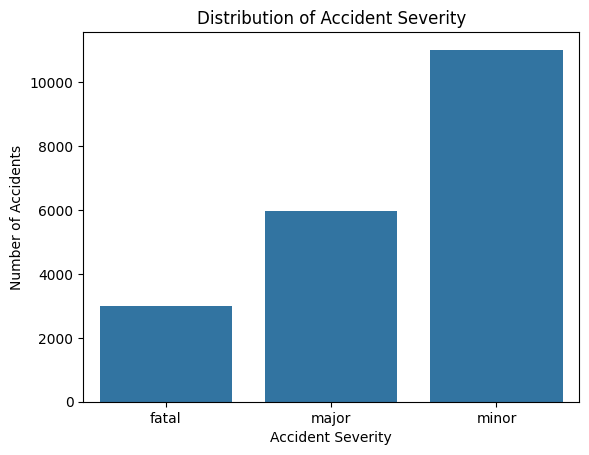

In [27]:
sns.countplot(
    data=df,
    x="accident_severity"
)

plt.title("Distribution of Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Number of Accidents")
plt.show()


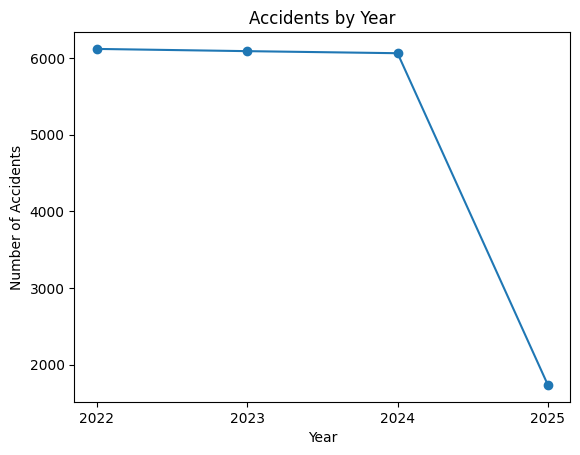

In [28]:
df["Year"] = df["date"].dt.year

df["Year"].value_counts().sort_index().plot( kind="line",  marker="o")

plt.title("Accidents by Year")
plt.xlabel("Year")
plt.ylabel("Number of Accidents")

plt.xticks(df["Year"].unique().astype(int))

plt.show()


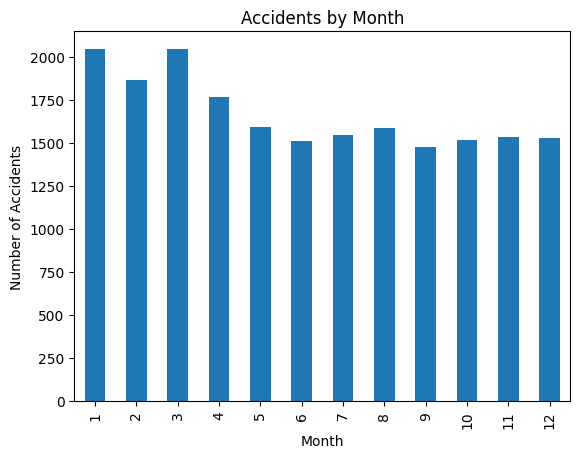

In [29]:
df["Month"] = df["date"].dt.month

df["Month"].value_counts().sort_index().plot(kind="bar")

plt.title("Accidents by Month")
plt.xlabel("Month")
plt.ylabel("Number of Accidents")
plt.show()


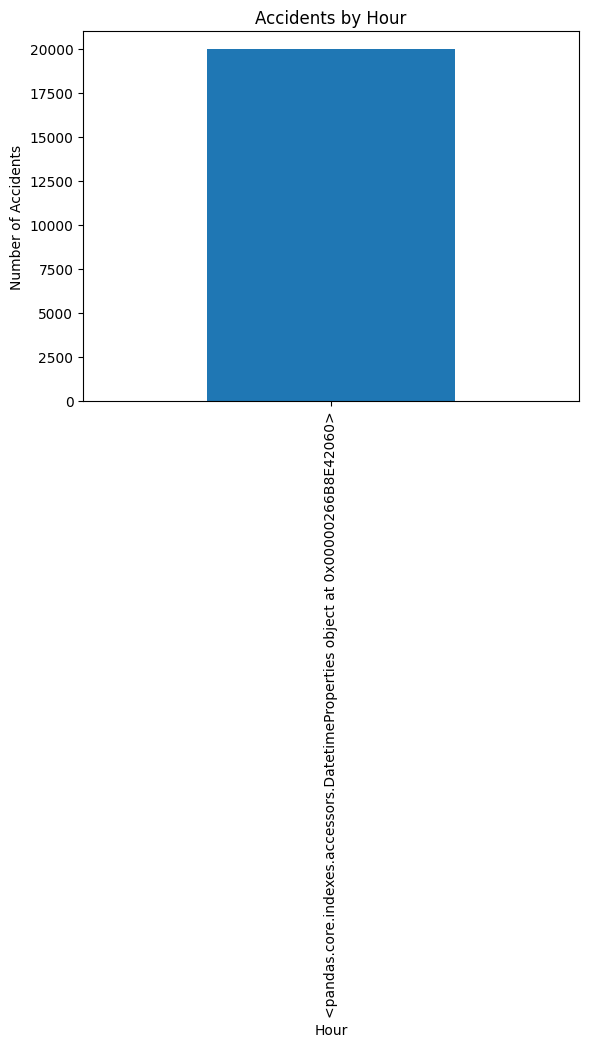

In [30]:

df["time"] = pd.to_datetime(
    df["time"], errors="coerce")

df["Hour"] = df["time"].dt

df["Hour"].value_counts().sort_index().plot(kind="bar")

plt.title("Accidents by Hour")
plt.xlabel("Hour")
plt.ylabel("Number of Accidents")
plt.show()


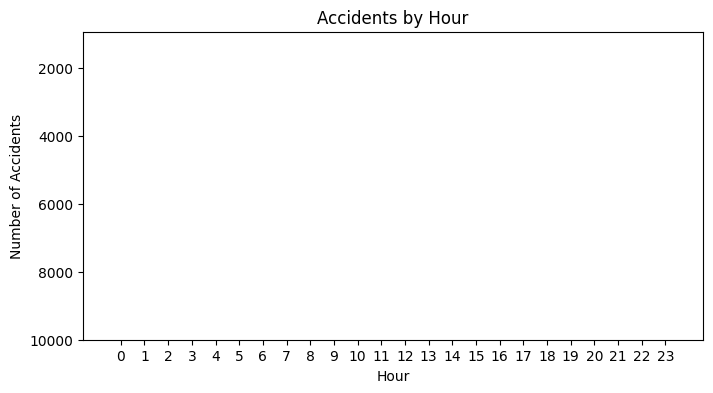

In [31]:
df["Hour"] = df["time"].dt.hour

hour_counts = df["Hour"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(hour_counts.index, hour_counts.values)

plt.title("Accidents by Hour")
plt.xlabel("Hour")
plt.ylabel("Number of Accidents")
plt.xticks(range(0, 24))
plt.ylim(bottom=10000)
plt.show()

In [32]:
severity_percentage = (
    df["accident_severity"]
    .value_counts(normalize=True)
    * 100
)

print(severity_percentage.round(2))


accident_severity
minor    55.12
major    29.94
fatal    14.94
Name: proportion, dtype: float64


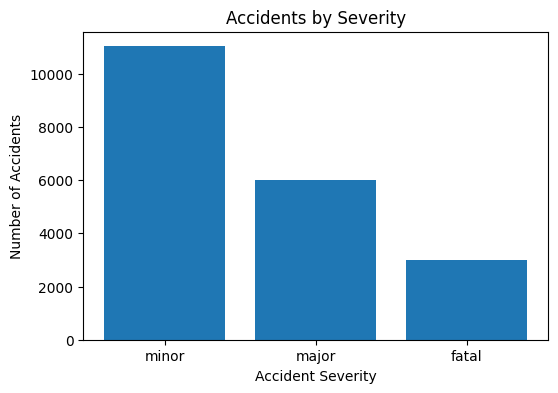

In [33]:
severity_counts = df["accident_severity"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(severity_counts.index.astype(str), severity_counts.values)

plt.title("Accidents by Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Number of Accidents")
plt.ylim(bottom=0)
plt.show()

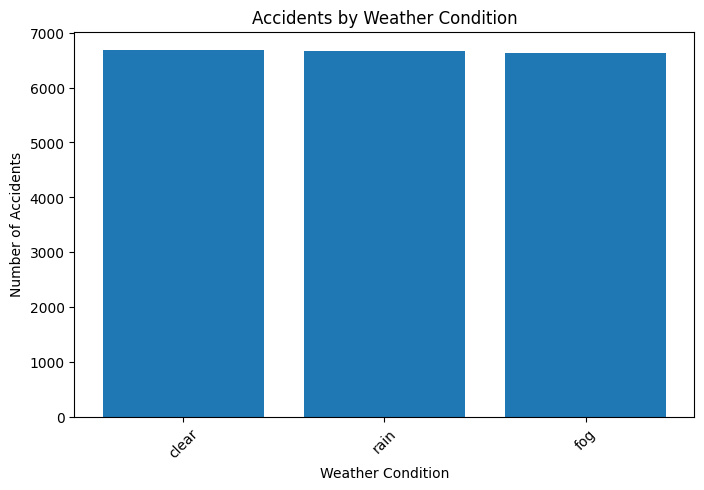

In [34]:
weather_counts = df["weather"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(
    weather_counts.index.astype(str),
    weather_counts.values
)

plt.title("Accidents by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.ylim(bottom=0)
plt.show()

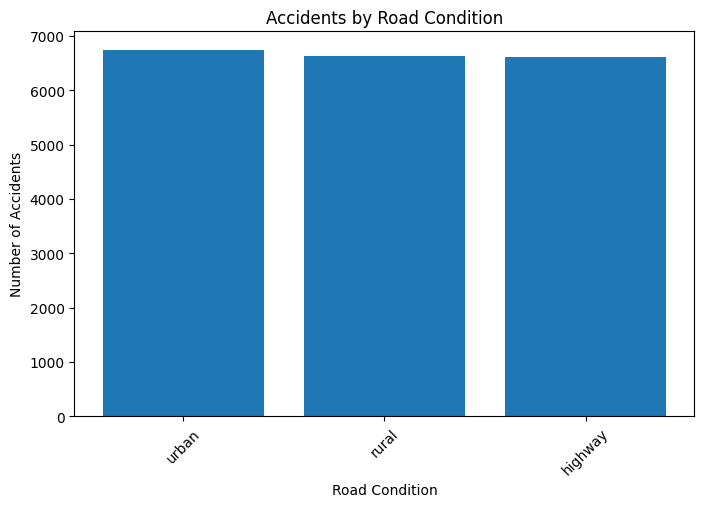

In [35]:
road_condition_counts = df["road_type"].value_counts()

plt.figure(figsize=(8,5))
plt.bar(
    road_condition_counts.index.astype(str),
    road_condition_counts.values
)

plt.title("Accidents by Road Condition")
plt.xlabel("Road Condition")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.ylim(bottom=0)
plt.show()

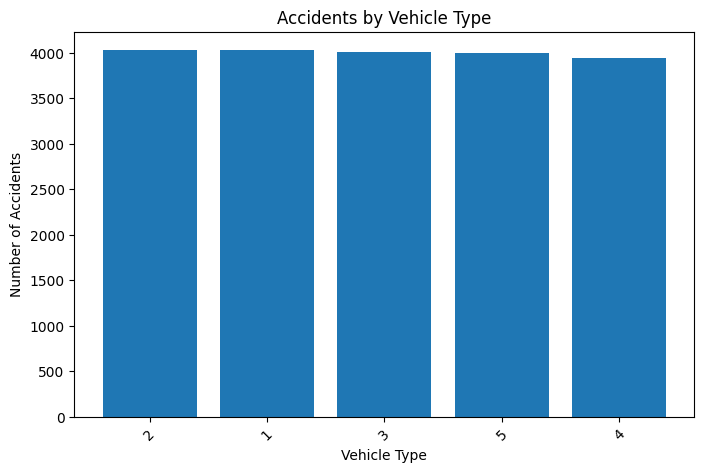

In [36]:
vehicle_counts = df["vehicles_involved"].value_counts()

plt.figure(figsize=(8,5))
plt.bar(
    vehicle_counts.index.astype(str),
    vehicle_counts.values
)

plt.title("Accidents by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.ylim(bottom=0)
plt.show()

In [37]:
cause_counts = df["cause"].value_counts()

print(cause_counts)


cause
distraction      4026
overspeeding     4025
weather          3997
drunk driving    3978
poor road        3974
Name: count, dtype: int64


C:\Users\Heena Praween\AppData\Local\Temp\ipykernel_13980\1830444815.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


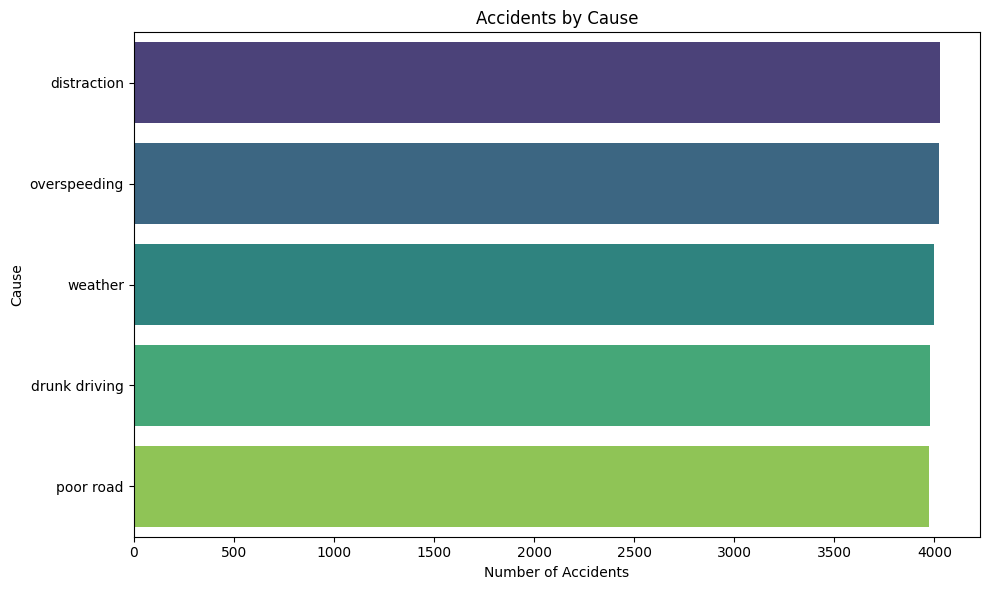

In [38]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="cause",
    order=df["cause"].value_counts().index,
    palette="viridis"
)

plt.title("Accidents by Cause")
plt.xlabel("Number of Accidents")
plt.ylabel("Cause")

plt.tight_layout()
plt.show()


In [39]:
print(df["traffic_density"].value_counts())


traffic_density
low       7067
high      7034
medium    5899
Name: count, dtype: int64


C:\Users\Heena Praween\AppData\Local\Temp\ipykernel_13980\1303845483.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


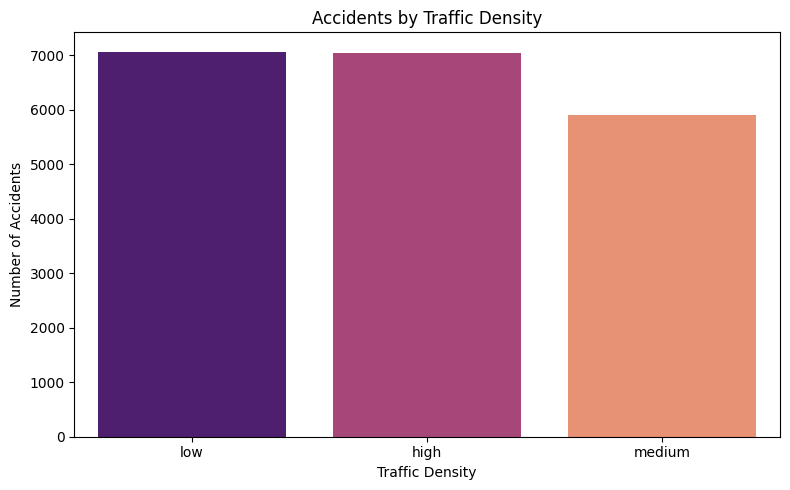

In [40]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="traffic_density",
    order=df["traffic_density"].value_counts().index,
    palette="magma"
)

plt.title("Accidents by Traffic Density")
plt.xlabel("Traffic Density")
plt.ylabel("Number of Accidents")

plt.tight_layout()
plt.show()


In [41]:
print(df["traffic_signal"].value_counts())


traffic_signal
0    10003
1     9997
Name: count, dtype: int64


C:\Users\Heena Praween\AppData\Local\Temp\ipykernel_13980\2028388879.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


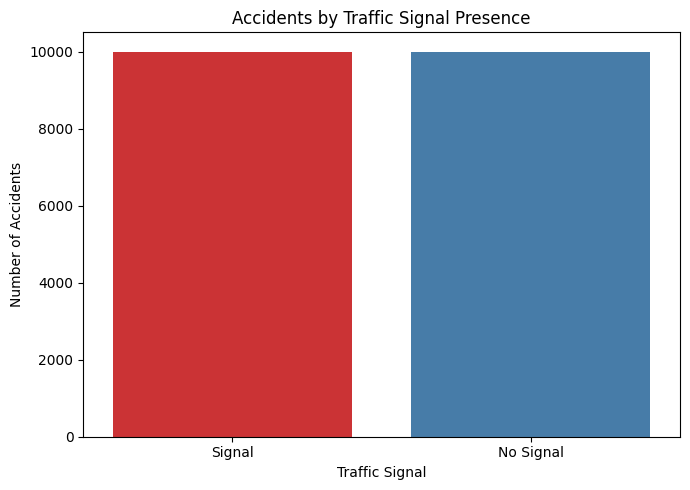

In [42]:
traffic_signal_labels = df["traffic_signal"].map({
    0: "No Signal",
    1: "Signal"
})

plt.figure(figsize=(7, 5))

sns.countplot(
    x=traffic_signal_labels,
    palette="Set1"
)

plt.title("Accidents by Traffic Signal Presence")
plt.xlabel("Traffic Signal")
plt.ylabel("Number of Accidents")

plt.tight_layout()
plt.show()


In [43]:
df["day_type"] = df["is_weekend"].map({
    0: "Weekday",
    1: "Weekend"
})


C:\Users\Heena Praween\AppData\Local\Temp\ipykernel_13980\1866997928.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


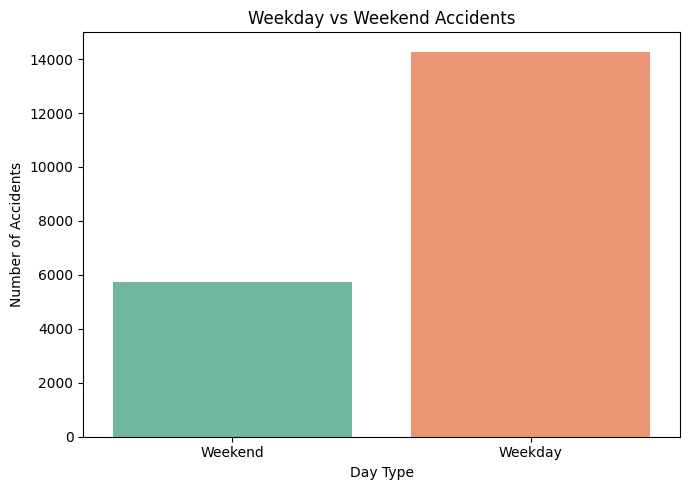

In [44]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="day_type",
    palette="Set2"
)

plt.title("Weekday vs Weekend Accidents")
plt.xlabel("Day Type")
plt.ylabel("Number of Accidents")

plt.tight_layout()
plt.show()


In [45]:
print(df["time_period"].value_counts())


time_period
Night    10052
Day       9948
Name: count, dtype: int64


C:\Users\Heena Praween\AppData\Local\Temp\ipykernel_13980\958361848.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


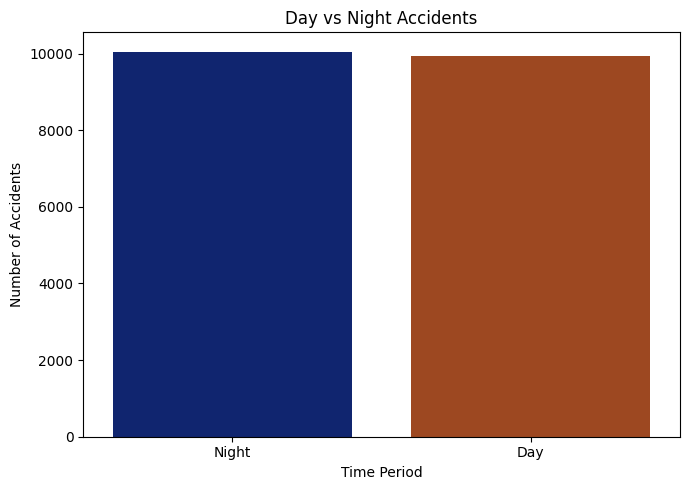

In [46]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="time_period",
    palette="dark"
)

plt.title("Day vs Night Accidents")
plt.xlabel("Time Period")
plt.ylabel("Number of Accidents")

plt.tight_layout()
plt.show()


In [47]:
df["peak_status"] = df["is_peak_hour"].map({
    0: "Non-Peak",
    1: "Peak"
})


C:\Users\Heena Praween\AppData\Local\Temp\ipykernel_13980\834667767.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


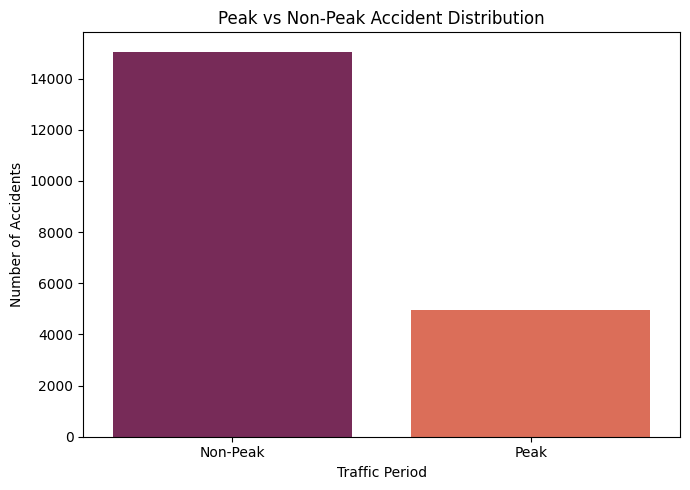

In [48]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="peak_status",
    palette="rocket"
)

plt.title("Peak vs Non-Peak Accident Distribution")
plt.xlabel("Traffic Period")
plt.ylabel("Number of Accidents")

plt.tight_layout()
plt.show()


In [49]:
print(df["visibility"].value_counts())


visibility
low       9987
high      6690
medium    3323
Name: count, dtype: int64


C:\Users\Heena Praween\AppData\Local\Temp\ipykernel_13980\1775821879.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


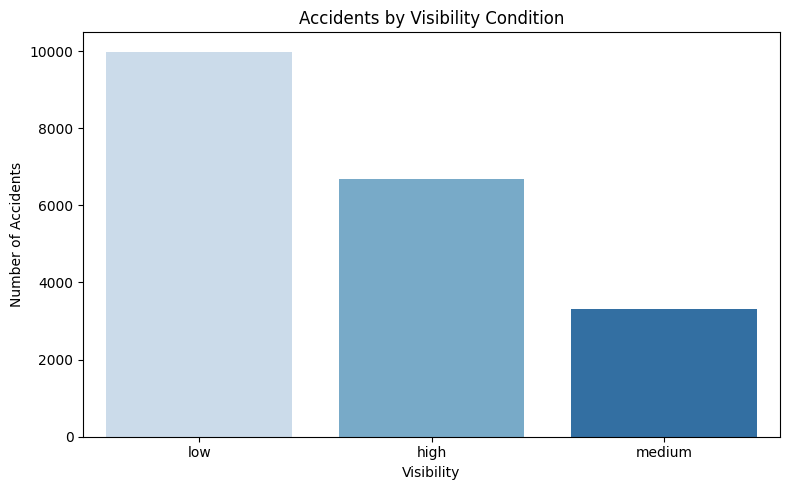

In [50]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="visibility",
    order=df["visibility"].value_counts().index,
    palette="Blues"
)

plt.title("Accidents by Visibility Condition")
plt.xlabel("Visibility")
plt.ylabel("Number of Accidents")

plt.tight_layout()
plt.show()


In [51]:

print(df["temperature"].describe())


count    20000.000000
mean        27.579600
std          7.454746
min         15.000000
25%         21.000000
50%         28.000000
75%         34.000000
max         40.000000
Name: temperature, dtype: float64


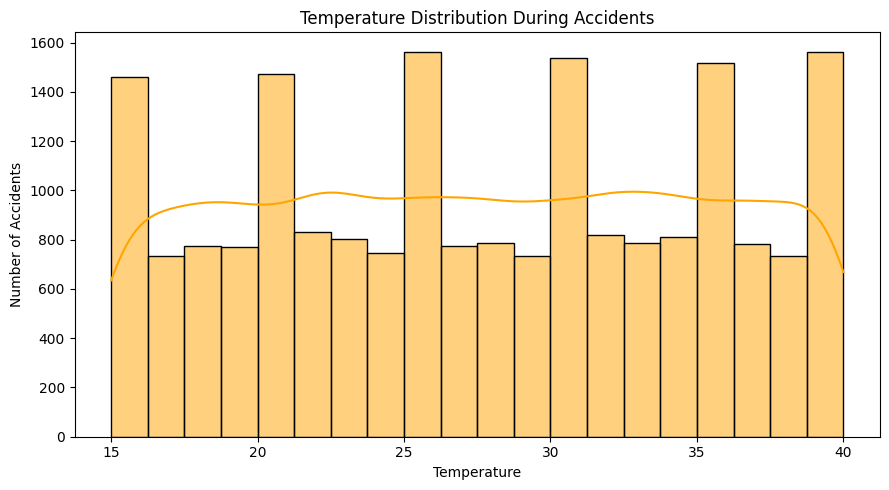

In [52]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="temperature",
    bins=20,
    kde=True,
    color="orange"
)

plt.title("Temperature Distribution During Accidents")
plt.xlabel("Temperature")
plt.ylabel("Number of Accidents")

plt.tight_layout()
plt.show()


In [45]:
print(df["casualties"].describe())


count    20000.000000
mean         1.726450
std          1.489104
min          0.000000
25%          1.000000
50%          1.000000
75%          3.000000
max          5.000000
Name: casualties, dtype: float64


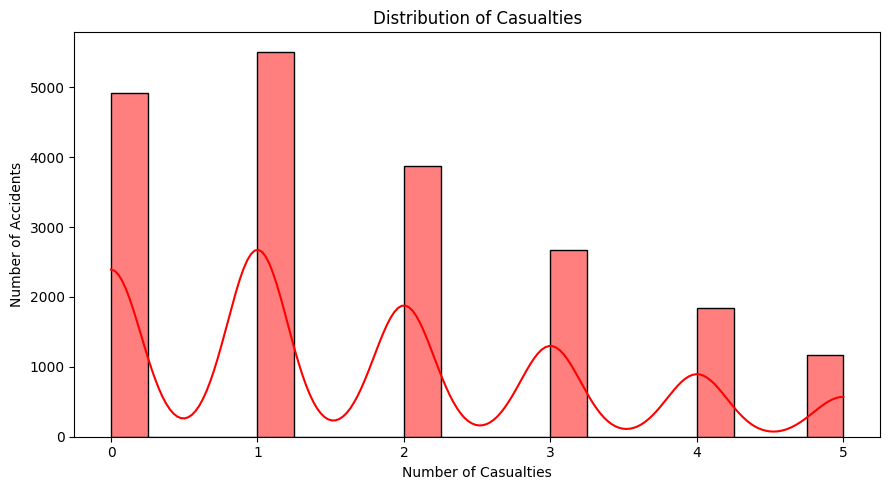

In [53]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="casualties",
    bins=20,
    kde=True,
    color="red"
)

plt.title("Distribution of Casualties")
plt.xlabel("Number of Casualties")
plt.ylabel("Number of Accidents")

plt.tight_layout()
plt.show()


C:\Users\Heena Praween\AppData\Local\Temp\ipykernel_13980\2976902170.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


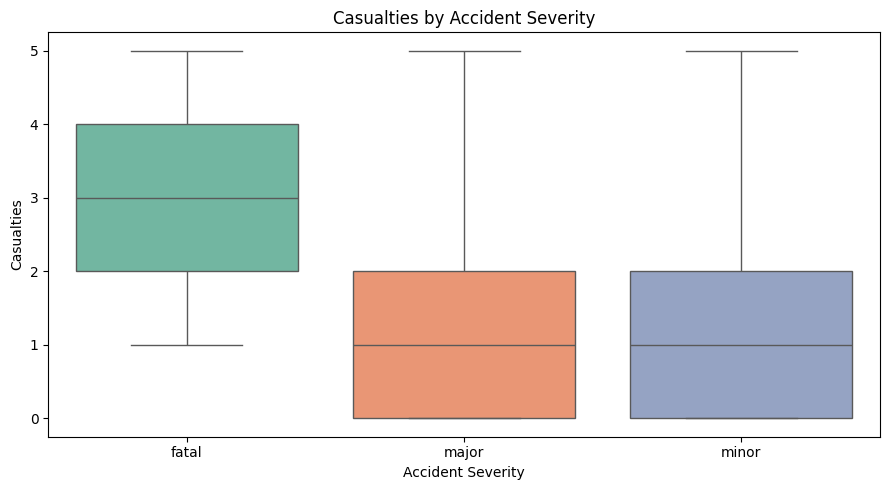

In [54]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="accident_severity",
    y="casualties",
    palette="Set2"
)

plt.title("Casualties by Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Casualties")

plt.tight_layout()
plt.show()


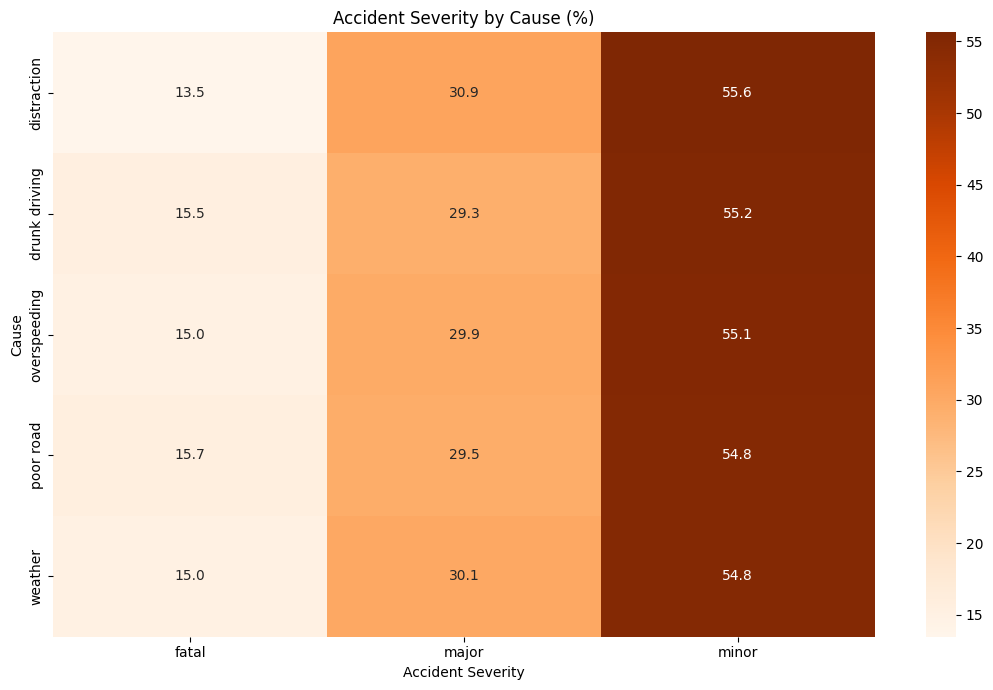

In [55]:
severity_cause = pd.crosstab(
    df["cause"],
    df["accident_severity"],
    normalize="index"
) * 100

plt.figure(figsize=(11, 7))

sns.heatmap(
    severity_cause,
    annot=True,
    fmt=".1f",
    cmap="Oranges"
)

plt.title("Accident Severity by Cause (%)")
plt.xlabel("Accident Severity")
plt.ylabel("Cause")

plt.tight_layout()
plt.show()


In [50]:
print(df["risk_score"].describe())


count    20000.000000
mean         0.437585
std          0.218130
min          0.100000
25%          0.250000
50%          0.450000
75%          0.600000
max          1.000000
Name: risk_score, dtype: float64


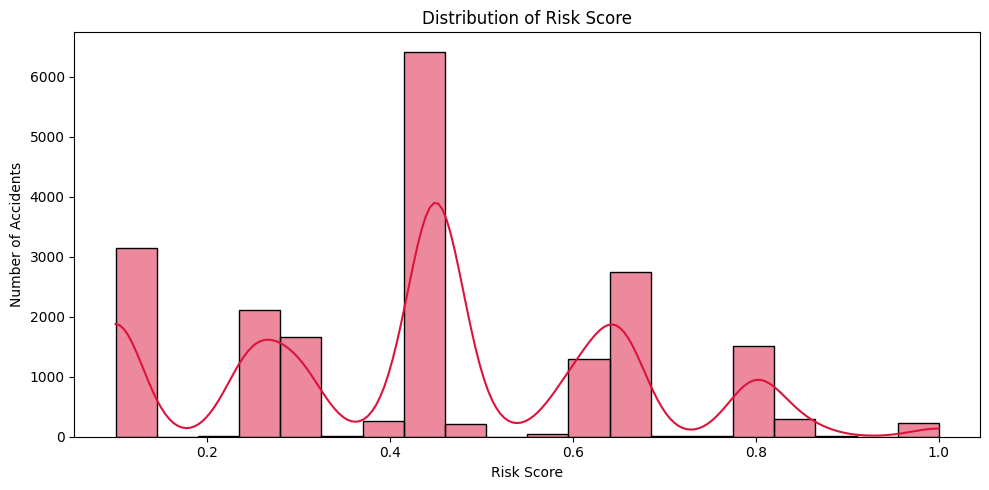

In [56]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="risk_score",
    bins=20,
    kde=True,
    color="crimson"
)

plt.title("Distribution of Risk Score")
plt.xlabel("Risk Score")
plt.ylabel("Number of Accidents")

plt.tight_layout()
plt.show()


In [57]:

city_counts = (
    df["city"]
    .value_counts()
    .head(15)
)

print(city_counts)


city
Chandigarh    2577
Chennai       2575
Kolkata       2559
Pune          2517
Mumbai        2492
Bangalore     2438
Delhi         2433
Hyderabad     2409
Name: count, dtype: int64


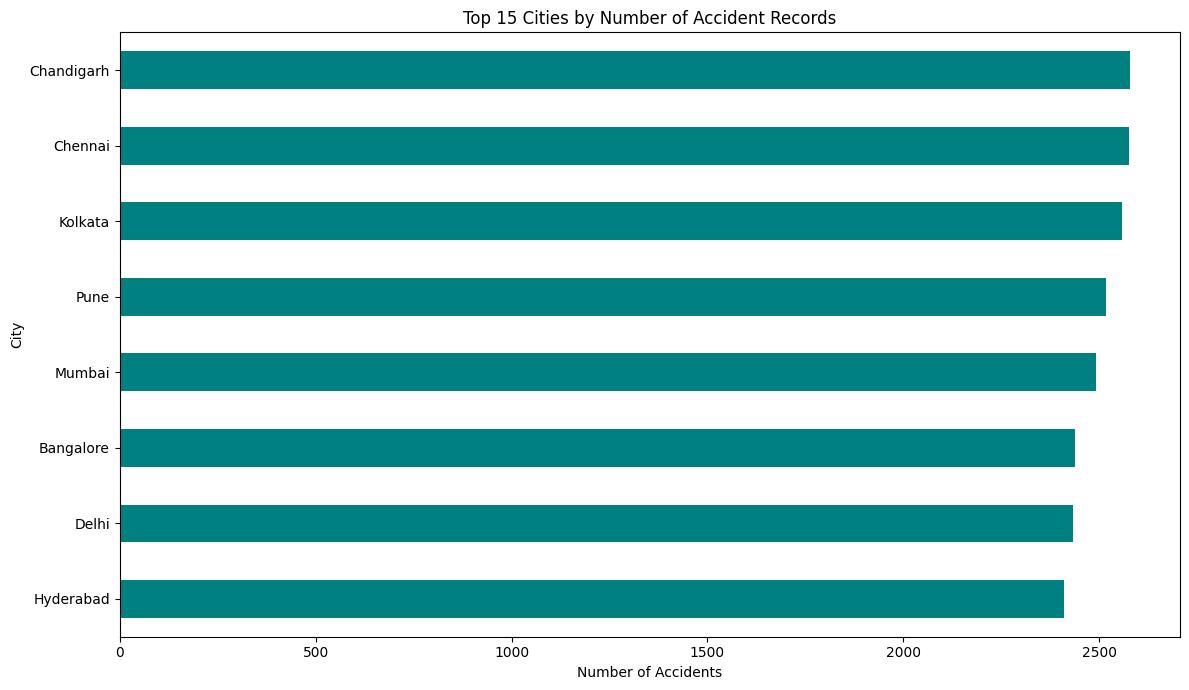

In [58]:
plt.figure(figsize=(12, 7))

city_counts.sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Top 15 Cities by Number of Accident Records")
plt.xlabel("Number of Accidents")
plt.ylabel("City")

plt.tight_layout()
plt.show()


In [59]:
state_counts = (
    df["state"]
    .value_counts()
    .head(15)
)

print(state_counts)


state
Maharashtra    5009
Punjab         2577
Tamil Nadu     2575
West Bengal    2559
Karnataka      2438
Delhi          2433
Telangana      2409
Name: count, dtype: int64


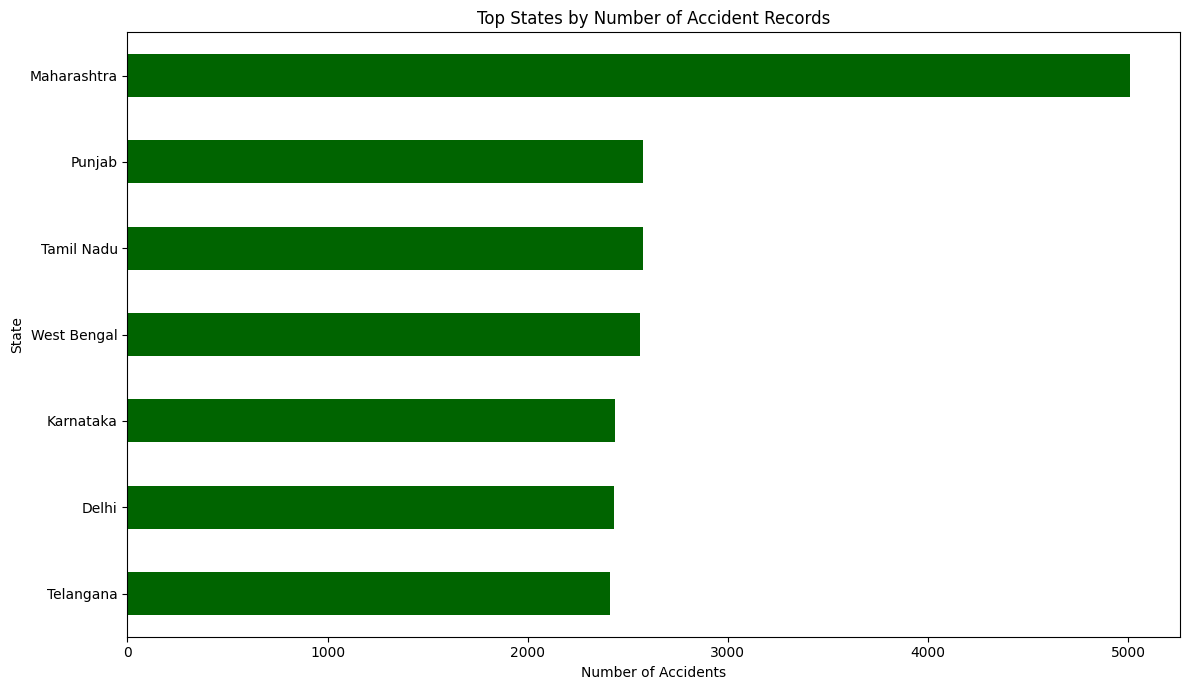

In [60]:
plt.figure(figsize=(12, 7))

state_counts.sort_values().plot(
    kind="barh",
    color="darkgreen"
)

plt.title("Top States by Number of Accident Records")
plt.xlabel("Number of Accidents")
plt.ylabel("State")

plt.tight_layout()
plt.show()


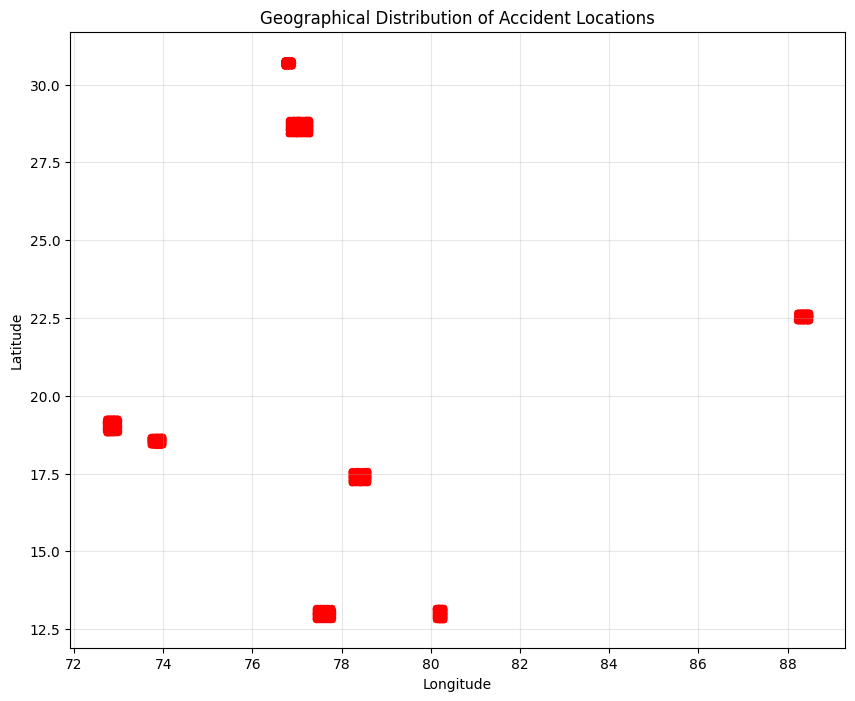

In [61]:
plt.figure(figsize=(10, 8))

plt.scatter(
    df["longitude"],
    df["latitude"],
    s=8,
    alpha=0.4,
    c="red"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Accident Locations")

plt.grid(alpha=0.3)

plt.show()


In [63]:
df["lat_bin"] = df["latitude"].round(2)
df["lon_bin"] = df["longitude"].round(2)


In [64]:
spatial_counts = (
    df.groupby(["lat_bin", "lon_bin"])
      .size()
      .reset_index(name="accident_count")
)

spatial_counts.sort_values(
    "accident_count",
    ascending=False
).head(20)


,lat_bin,lon_bin,accident_count
8290,30.76,76.89,17
8346,30.79,76.83,14
8052,30.65,76.79,13
8182,30.71,76.86,13
8077,30.66,76.83,13
8183,30.71,76.87,13
8095,30.67,76.80,12
7967,30.61,76.77,12
8350,30.79,76.87,12
8082,30.66,76.88,12


In [66]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns

correlation = df[numeric_cols].corr()


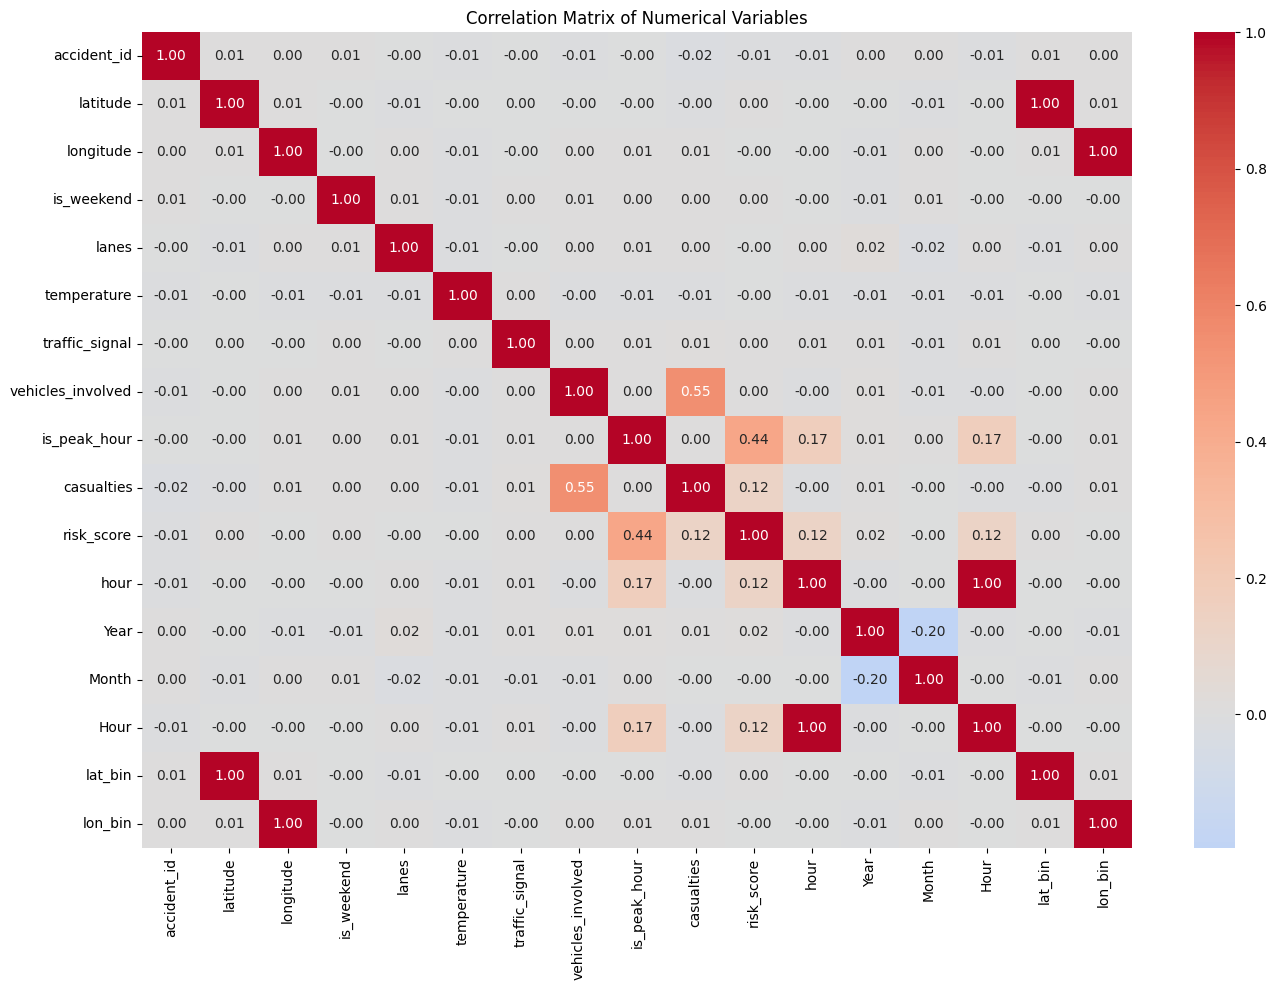

In [67]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Variables")

plt.tight_layout()
plt.show()


In [68]:
eda_summary = {
    "Total accidents": len(df),
    "Total cities": df["city"].nunique(),
    "Total states": df["state"].nunique(),
    "Total causes": df["cause"].nunique(),
    "Total road types": df["road_type"].nunique(),
    "Average casualties": df["casualties"].mean(),
    "Average vehicles involved": df["vehicles_involved"].mean(),
    "Average risk score": df["risk_score"].mean()
}

summary_df = pd.DataFrame(
    eda_summary.items(),
    columns=["Metric", "Value"]
)

print(summary_df)


                      Metric         Value
0            Total accidents  20000.000000
1               Total cities      8.000000
2               Total states      7.000000
3               Total causes      5.000000
4           Total road types      3.000000
5         Average casualties      1.726450
6  Average vehicles involved      2.992000
7         Average risk score      0.437585
